#**Rice Leaf Disease Project**

#Imports & Setup

In [51]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import KFold
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

#Configuration

In [50]:
img_size = 224
batch_size = 16
dataset_path = "/content/drive/MyDrive/PRCP-1001-RiceLeaf/Data"
num_classes = len(os.listdir(dataset_path))
epochs = 20

#Load Dataset

In [52]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size = img_size,
    batch_size = batch_size,
    shuffle=True
)

class_names = dataset.class_names

Found 119 files belonging to 3 classes.


#EDA (Exploratory Data Analysis)

Check classes & counts:

In [53]:
classes = os.listdir(dataset_path)
print("Classes:", classes)

for cls in classes:
    cls_path = os.path.join(dataset_path, cls)
    print(cls, "→", len(os.listdir(cls_path)), "images")

Classes: ['Leaf smut-20200814T055530Z-001', 'Brown spot-20200814T055208Z-001', 'Bacterial leaf blight-20200814T055237Z-001']
Leaf smut-20200814T055530Z-001 → 1 images
Brown spot-20200814T055208Z-001 → 1 images
Bacterial leaf blight-20200814T055237Z-001 → 1 images


#Class Distribution

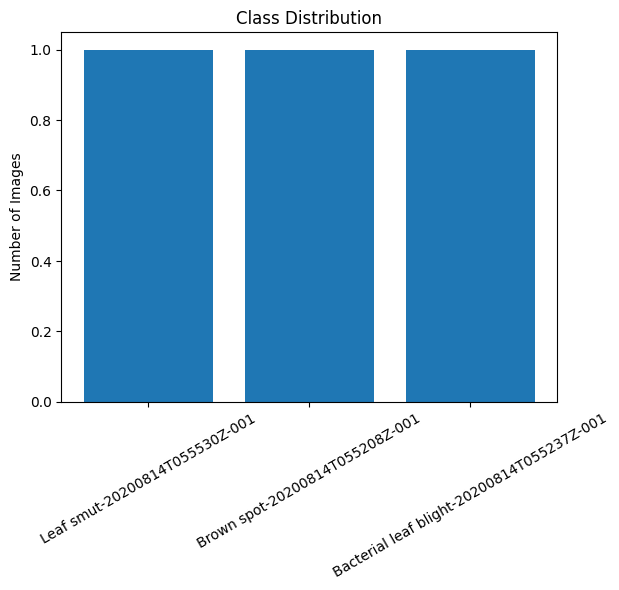

In [13]:
counts = []
for cls in classes:
    counts.append(len(os.listdir(os.path.join(dataset_path, cls))))

plt.bar(classes, counts)
plt.title("Class Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.show()

Interpretation

Large imbalance → Use class weights / augmentation

Balanced → Standard training OK

#Visual Inspection (Data Quality Check)

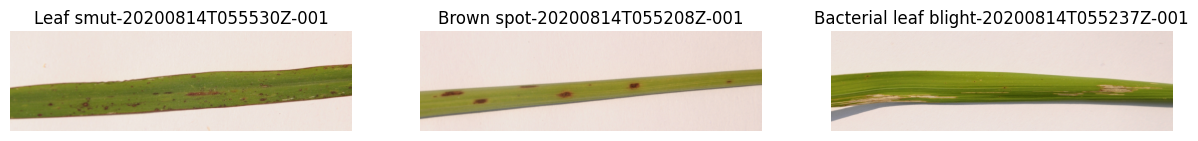

In [19]:
# Always manually inspect samples.
from PIL import Image
import matplotlib.pyplot as plt
import random
import os

plt.figure(figsize=(15, 5))

for i, cls in enumerate(classes):
    base_class_dir = os.path.join(dataset_path, cls)
    first_level_contents = os.listdir(base_class_dir)
    actual_image_source_dir = base_class_dir

    if len(first_level_contents) == 1 and os.path.isdir(os.path.join(base_class_dir, first_level_contents[0])):
        actual_image_source_dir = os.path.join(base_class_dir, first_level_contents[0])
    try:
        image_files = [f for f in os.listdir(actual_image_source_dir) if os.path.isfile(os.path.join(actual_image_source_dir, f))]

        if image_files:
            img_name = random.choice(image_files)
            img_path = os.path.join(actual_image_source_dir, img_name)

            img = Image.open(img_path)

            plt.subplot(1, len(classes), i+1)
            plt.imshow(img)
            plt.title(cls)
            plt.axis("off")
        else:
            print(f"No image files found in {actual_image_source_dir}")
            plt.subplot(1, len(classes), i+1)
            plt.text(0.5, 0.5, "No Images", horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes)
            plt.title(cls)
            plt.axis("off")

    except FileNotFoundError:
        print(f"Directory not found: {actual_image_source_dir}")
        plt.subplot(1, len(classes), i+1)
        plt.text(0.5, 0.5, "Dir Not Found", horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes)
        plt.title(cls)
        plt.axis("off")
    except Exception as e:
        print(f"An error occurred for class {cls}: {e}")
        plt.subplot(1, len(classes), i+1)
        plt.text(0.5, 0.5, f"Error: {e}", horizontalalignment='center', verticalalignment='center', transform=plt.gca().transAxes)
        plt.title(cls)
        plt.axis("off")

plt.show()

#Image Size Analysis

In [55]:
sizes = []

for cls in classes:
    base_class_dir = os.path.join(dataset_path, cls)
    first_level_contents = os.listdir(base_class_dir)
    actual_image_source_dir = base_class_dir

    if len(first_level_contents) == 1 and os.path.isdir(os.path.join(base_class_dir, first_level_contents[0])):
        actual_image_source_dir = os.path.join(base_class_dir, first_level_contents[0])

    for img_name in os.listdir(actual_image_source_dir):
        img_path = os.path.join(actual_image_source_dir, img_name)
        if os.path.isfile(img_path):
            img = Image.open(img_path)
            sizes.append(img.size)

print("Unique Image Sizes:", set(sizes))

Unique Image Sizes: {(537, 216), (503, 174), (367, 73), (562, 217), (763, 268), (946, 255), (768, 514), (427, 193), (617, 244), (296, 88), (340, 94), (316, 127), (699, 197), (467, 104), (510, 383), (1200, 900), (1504, 323), (948, 233), (286, 92), (311, 170), (359, 168), (766, 250), (565, 233), (741, 291), (250, 200), (614, 409), (765, 224), (301, 71), (376, 80), (456, 124), (1480, 279), (948, 211), (3081, 897), (1530, 371)}


Interpretation

Many different sizes → Resize required (normal)

Extremely small images → Quality concern

#Aspect Ratio Check

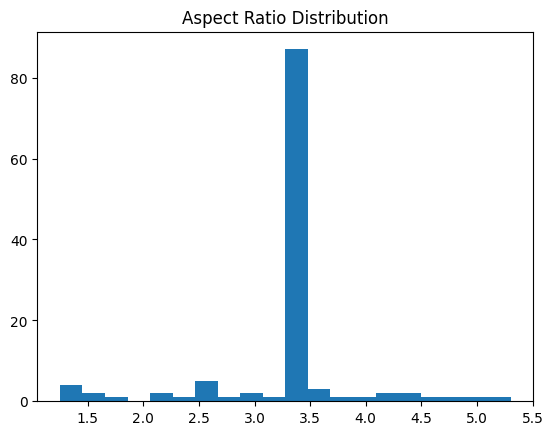

In [56]:
ratios = [w/h for (w, h) in sizes]

plt.hist(ratios, bins=20)
plt.title("Aspect Ratio Distribution")
plt.show()

#Pixel Intensity Distribution

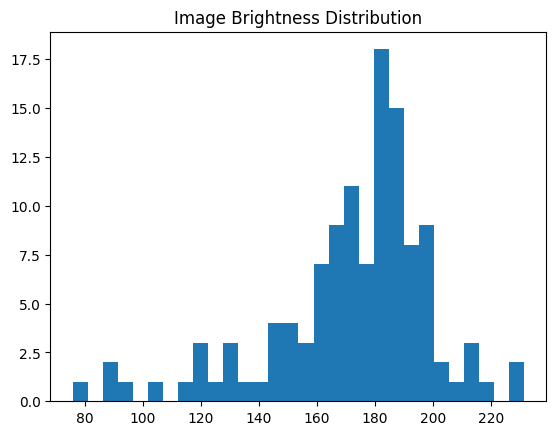

In [58]:
import numpy as np

pixels = []

for cls in classes:
    base_class_dir = os.path.join(dataset_path, cls)
    first_level_contents = os.listdir(base_class_dir)
    actual_image_source_dir = base_class_dir

    if len(first_level_contents) == 1 and os.path.isdir(os.path.join(base_class_dir, first_level_contents[0])):
        actual_image_source_dir = os.path.join(base_class_dir, first_level_contents[0])

    for img_name in os.listdir(actual_image_source_dir):
        img_path = os.path.join(actual_image_source_dir, img_name)
        if os.path.isfile(img_path):
            img = Image.open(img_path)
            img = np.array(img)
            pixels.append(img.mean())

plt.hist(pixels, bins=30)
plt.title("Image Brightness Distribution")
plt.show()

#Duplicate Detection

In [64]:
import hashlib
import os

hash_dict = {}
duplicates = []

for cls in classes:
    base_class_dir = os.path.join(dataset_path, cls)
    first_level_contents = os.listdir(base_class_dir)
    actual_image_source_dir = base_class_dir

    if len(first_level_contents) == 1 and os.path.isdir(os.path.join(base_class_dir, first_level_contents[0])):
        actual_image_source_dir = os.path.join(base_class_dir, first_level_contents[0])

    for img_name in os.listdir(actual_image_source_dir):
        img_path = os.path.join(actual_image_source_dir, img_name)
        if os.path.isfile(img_path):
            with open(img_path, 'rb') as f:
                filehash = hashlib.md5(f.read()).hexdigest()

            if filehash in hash_dict:
                duplicates.append((img_path, hash_dict[filehash]))
            else:
                hash_dict[filehash] = img_path

if duplicates:
    print("\nDuplicates Found:")
    for dup in duplicates:
        print(dup)
else:
    print("\nNo duplicates detected.")


No duplicates detected.


In [62]:
total_images = sum(counts)
print("\nTotal Images:", total_images)
print("Number of Classes:", len(classes))


Total Images: 3
Number of Classes: 3


#Data Augmentation

In [5]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

#Build Model Function

In [33]:
def build_model(hp=None):

    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3)
    )
    base_model.trainable = False

    inputs = keras.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = layers.Lambda(tf.keras.applications.efficientnet.preprocess_input, name='preprocess_input_layer')(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)

    if hp:
        units = hp.Int("units", min_value=64, max_value=256, step=64)
        dropout = hp.Float("dropout", 0.2, 0.5, step=0.1)
    else:
        units = 128
        dropout = 0.3

    x = layers.Dense(units, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs)

    if hp:
        lr = hp.Choice("lr", [1e-2, 1e-3, 1e-4])
    else:
        lr = 1e-3

    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [9]:
!pip install keras-tuner

#Hyperparameter Tuning

In [40]:
import keras_tuner as kt

tuner = kt.RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=5,
    directory="tuner_dir",
    project_name="rice_disease"
)
total_batches = tf.data.experimental.cardinality(dataset).numpy()
val_batches = int(total_batches * 0.2)

train_ds = dataset.skip(val_batches)
val_ds = dataset.take(val_batches)

tuner.search(train_ds, validation_data=val_ds, epochs=10)
best_model = tuner.get_best_models(1)[0]

Reloading Tuner from tuner_dir/rice_disease/tuner0.json


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


#Train Best Model

In [41]:
history = best_model.fit(train_ds, epochs=epochs, validation_data=val_ds)

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.9245 - loss: 0.3685 - val_accuracy: 1.0000 - val_loss: 0.0172
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.8922 - loss: 0.3159 - val_accuracy: 0.8125 - val_loss: 0.6383
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.8897 - loss: 0.6128 - val_accuracy: 1.0000 - val_loss: 0.0656
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.8674 - loss: 0.3751 - val_accuracy: 1.0000 - val_loss: 0.0269
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9142 - loss: 0.1602 - val_accuracy: 1.0000 - val_loss: 0.0076
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9476 - loss: 0.1110 - val_accuracy: 1.0000 - val_loss: 0.0264
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9731 - loss: 0.0885 - val_accuracy: 1.0000 - val_loss: 0.0033
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9368 - loss: 0.3795 - val_accuracy: 1.0000 - val_loss: 0.0128
Epoch 9/2

#K-Fold Cross Validation

In [24]:
images = []
labels = []

for batch_images, batch_labels in dataset.unbatch():
    images.append(batch_images.numpy())
    labels.append(batch_labels.numpy())

images = np.array(images)
labels = np.array(labels)

kf = KFold(n_splits=5, shuffle=True)

fold = 1
for train_idx, val_idx in kf.split(images):

    print(f"\nFold {fold}")
    model = build_model()

    model.fit(
        images[train_idx], labels[train_idx],
        validation_data=(images[val_idx], labels[val_idx]),
        epochs=10,
        batch_size = batch_size,
        verbose=0
    )

    fold += 1


Fold 1

Fold 2

Fold 3

Fold 4

Fold 5


#Fine-Tuning

In [25]:
best_model.layers[3].trainable = True

best_model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

best_model.fit(dataset, epochs=5)

Epoch 1/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 1.0000 - loss: 0.0051
Epoch 2/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 1.0000 - loss: 0.0120
Epoch 3/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 1.0000 - loss: 0.0098
Epoch 4/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 980ms/step - accuracy: 1.0000 - loss: 0.0051
Epoch 5/5
8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 956ms/step - accuracy: 1.0000 - loss: 0.0054


#Evaluation

In [26]:
pred_probs = best_model.predict(images)
pred_labels = np.argmax(pred_probs, axis=1)

print(classification_report(labels, pred_labels, target_names=class_names))

4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step
                                            precision    recall  f1-score   support

Bacterial leaf blight-20200814T055237Z-001       1.00      1.00      1.00        40
           Brown spot-20200814T055208Z-001       1.00      1.00      1.00        40
            Leaf smut-20200814T055530Z-001       1.00      1.00      1.00        39

                                  accuracy                           1.00       119
                                 macro avg       1.00      1.00      1.00       119
                              weighted avg       1.00      1.00      1.00       119



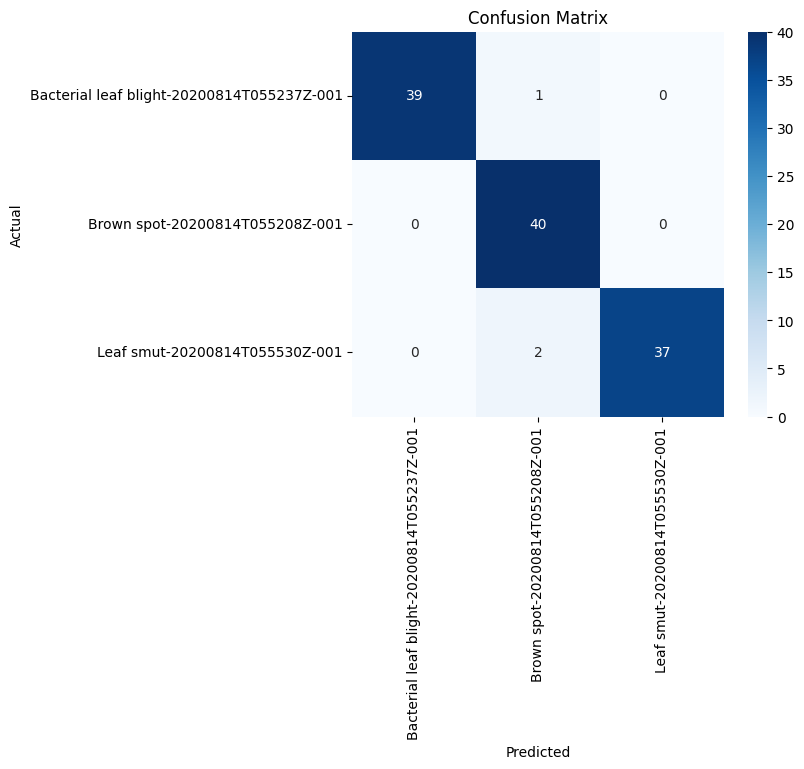

In [94]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(labels, pred_labels)

#Plot
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

#ROC Curve Per Class

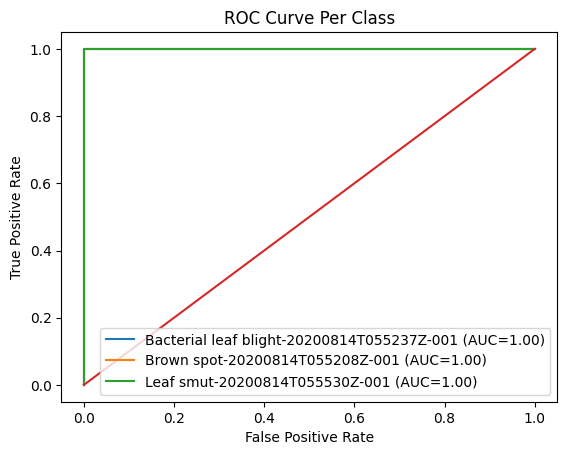

In [27]:
labels_bin = label_binarize(labels, classes=range(num_classes))

for i in range(num_classes):
    fpr, tpr, _ = roc_curve(labels_bin[:, i], pred_probs[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.2f})")

plt.plot([0, 1], [0, 1])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.title("ROC Curve Per Class")
plt.show()

#Grad-CAM

In [69]:
import numpy as np

pred_probs = model.predict(images)
pred_labels = np.argmax(pred_probs, axis=1)

4/4 ━━━━━━━━━━━━━━━━━━━━ 18s 3s/step


In [70]:
misclassified_indices = np.where(pred_labels != labels)[0]

print("Number of Misclassified Images:", len(misclassified_indices))

idx = misclassified_indices[0]
print("Selected Index:", idx)
print("True Label:", class_names[labels[idx]])
print("Predicted Label:", class_names[pred_labels[idx]])

Number of Misclassified Images: 3
Selected Index: 6
True Label: Leaf smut-20200814T055530Z-001
Predicted Label: Brown spot-20200814T055208Z-001


#Grad-CAM Function

In [81]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    preprocess_input_layer = model.get_layer('preprocess_input_layer')
    efficientnet_backbone_layer = model.get_layer('efficientnetb0')

    grad_cam_input = keras.Input(shape=(img_size, img_size, 3), name="grad_cam_image_input")
    x_for_backbone = preprocess_input_layer(grad_cam_input)
    features_output = efficientnet_backbone_layer(x_for_backbone, training=False)

    feature_extractor = tf.keras.Model(
        inputs=grad_cam_input,
        outputs=features_output
    )

    with tf.GradientTape() as tape:
        conv_outputs = feature_extractor(img_array)
        tape.watch(conv_outputs)
        predictions = model(img_array, training=False)
        class_idx = tf.argmax(predictions[0])
        loss = predictions[:, class_idx]
    grads = tape.gradient(loss, conv_outputs)

    if grads is None:
        tf.print("Warning: Gradients are None. Check model architecture and Grad-CAM target layer.")
        if conv_outputs is not None and conv_outputs.shape:
             return np.zeros(conv_outputs[0].shape[:-1], dtype=np.float32)
        else:
            return np.zeros((7, 7), dtype=np.float32)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    max_val = tf.reduce_max(heatmap)
    if max_val == 0:
        return heatmap.numpy()
    heatmap = tf.maximum(heatmap, 0) / max_val

    return heatmap.numpy()

In [82]:
img = images[idx]
img_array = np.expand_dims(img, axis=0)

Generate Heatmap

In [89]:
heatmap = make_gradcam_heatmap(img_array, best_model, last_conv_layer_name="top_activation")
print("Heatmap Shape:", heatmap.shape)

Heatmap Shape: (7, 7)


In [84]:
for layer in model.layers:
    print(layer.name)

input_layer_11
sequential
efficientnetb0
global_average_pooling2d_5
dense_10
dropout_5
dense_11


#Overlay Heatmap

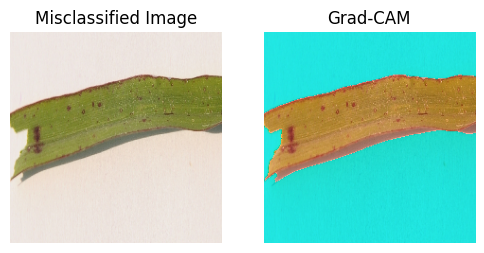

In [91]:
import cv2
import matplotlib.pyplot as plt

heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
heatmap_uint8 = np.uint8(255 * heatmap_resized)

colored_heatmap = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)

superimposed_img = colored_heatmap * 0.4 + img
superimposed_img = np.uint8(superimposed_img)

plt.figure(figsize=(6, 4))

plt.subplot(1, 2, 1)
plt.imshow(img.astype("uint8"))
plt.title("Misclassified Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(superimposed_img)
plt.title("Grad-CAM")
plt.axis("off")

plt.show()